In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
X, y = make_classification(
    n_samples=2000,
    n_features=5,
    n_informative=4,
    n_redundant=1,
    weights=[0.8, 0.2],
    random_state=42
)

df = pd.DataFrame(
    X,
    columns=["biomarker_1", "biomarker_2",
             "biomarker_3", "biomarker_4", "biomarker_5"]
)

df["disease"] = y

df.head()

,biomarker_1,biomarker_2,biomarker_3,biomarker_4,biomarker_5,disease
0,-2.408675,-0.650034,-0.160309,-1.599663,-0.672068,0
1,-0.709557,-1.619217,-1.209135,0.147576,-1.514795,0
2,1.162556,0.612274,-0.032095,-0.203195,0.713164,1
3,0.053652,-0.615724,-0.922900,-1.377006,-0.492133,1
4,1.179233,-0.708842,-1.688130,1.981509,-0.064364,0


In [ ]:
df["disease"].value_counts()

,count
disease,
0,1596
1,404


Performs a 80:20 split (training:test set)

In [ ]:
train_random, test_random = train_test_split(
    df,
    test_size=0.2,
    random_state=42
)

In [ ]:
# check the distribution
print("Training set:")
print(train_random["disease"].value_counts())

print("\nTesting set:")
print(test_random["disease"].value_counts())

Training set:
disease
0    1280
1     320
Name: count, dtype: int64

Testing set:
disease
0    316
1     84
Name: count, dtype: int64


In [ ]:
print("Original proportions:")
print(df["disease"].value_counts(normalize=True)) # Normalize=True gives proportion instead of count

print("\nTest set proportions:")
print(test_random["disease"].value_counts(normalize=True))

Original proportions:
disease
0    0.798
1    0.202
Name: proportion, dtype: float64

Test set proportions:
disease
0    0.79
1    0.21
Name: proportion, dtype: float64


## Stratified sampling

Now let's repeat the split, but preserve the proportion of each class.

In [ ]:
train_strat, test_strat = train_test_split(
    df,
    test_size=0.2,
    stratify=df["disease"], # It ensures that the split preserves the original ratio of
                            # healthy-to-disease cases (approximately 80:20 in the dataset) in both
                            # the resulting training and testing subsets.
    random_state=42
)

In [ ]:
print("Training proportions:")
print(train_strat["disease"].value_counts(normalize=True))

print("\nTesting proportions:")
print(test_strat["disease"].value_counts(normalize=True))
# in this both training and testing samples have approximately the same 0 to 1 proportions cuz of stratified.

Training proportions:
disease
0    0.798125
1    0.201875
Name: proportion, dtype: float64

Testing proportions:
disease
0    0.7975
1    0.2025
Name: proportion, dtype: float64


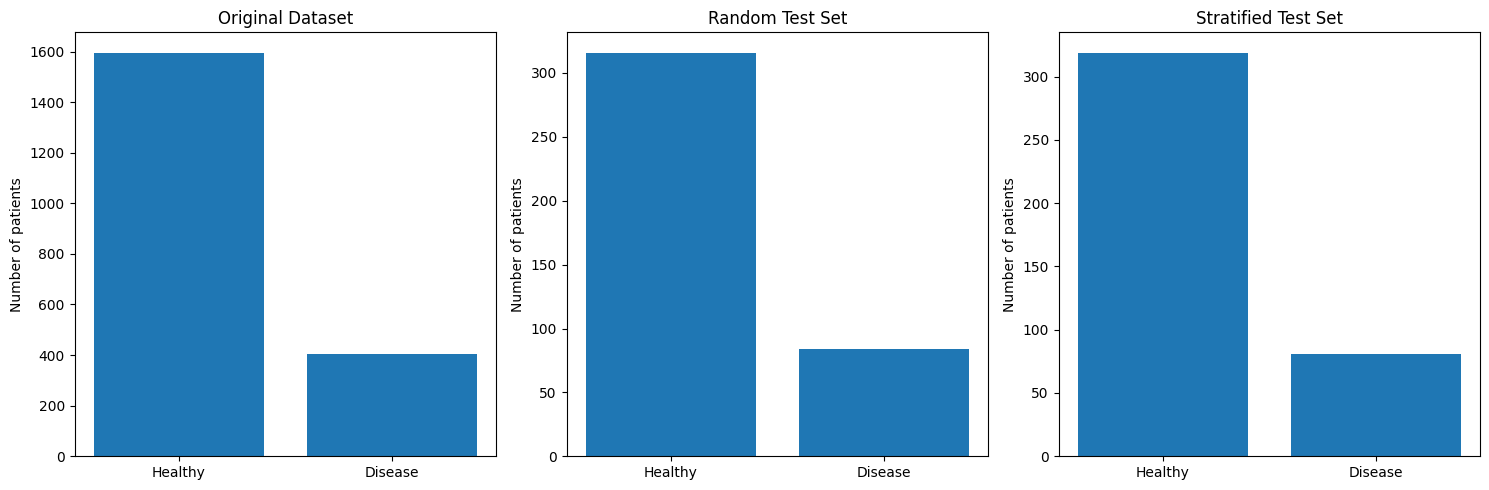

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

datasets = [
    (df, "Original Dataset"),
    (test_random, "Random Test Set"),
    (test_strat, "Stratified Test Set")
]

for ax, (data, title) in zip(axes, datasets):
    counts = data["disease"].value_counts().sort_index()

    ax.bar(["Healthy", "Disease"], counts.values)
    ax.set_title(title)
    ax.set_ylabel("Number of patients")

plt.tight_layout()
plt.show()

### Stratified Sampling vs Random Sampling

**Random Sampling:**
- Randomly selects samples from the dataset without considering class proportions.
- The proportions of each class in the resulting train/test sets may differ slightly from the original dataset.
- May result in an unrepresentative split, especially with small or imbalanced datasets.

**Stratified Sampling:**
- Divides the dataset while preserving the proportion of each class.
- Ensures that both classes are represented in the train/test sets in approximately the same ratio as the original dataset.
- Particularly useful for imbalanced datasets, such as disease detection.

#### Comparison Example (for an 80:20 train-test split with 2,000 patients):

| Dataset | Healthy | Disease-positive |
| :--- | :---: | :---: |
| **Original** | 80% (1,600) | 20% (400) |
| **Random test set** | *May vary* | *May vary* |
| **Stratified test set** | 80% | 20% |

# cross validation

In [ ]:
# splitting the data
X = df.drop("disease", axis=1)
y = df["disease"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

In [ ]:
# checking the sizes
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1600
Testing samples: 400


In [ ]:
# create a 5-fold cross-validator
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [ ]:
for fold, (train_index, val_index) in enumerate(
    skf.split(X_train, y_train)
):
    print(f"Fold {fold + 1}")
    print("Training samples:", len(train_index))
    print("Validation samples:", len(val_index))
    print("--------------------")

Fold 1
Training samples: 1280
Validation samples: 320
--------------------
Fold 2
Training samples: 1280
Validation samples: 320
--------------------
Fold 3
Training samples: 1280
Validation samples: 320
--------------------
Fold 4
Training samples: 1280
Validation samples: 320
--------------------
Fold 5
Training samples: 1280
Validation samples: 320
--------------------


**Summary of Stratified K-Fold Splitting**

The loop above splits our **1,600 training samples** into **5 separate folds** to evaluate model performance:

* **Equal Size**: For each of the 5 folds, the data is partitioned cleanly into **1,280 samples** for training and **320 samples** for validation.
* **Stratified Proportions**: Using `StratifiedKFold` guarantees that each individual fold preserves the same target class distribution (~20% disease cases) as the parent training dataset, preventing bias during validation.

In [ ]:
model = make_pipeline(
    StandardScaler(), # This is a preprocessing step that standardizes your features by scaling them
                      # so they have a mean of 0 and a variance of 1. This is crucial for Logistic
                      # Regression to perform optimally and converge quickly.
    LogisticRegression(max_iter=1000) # This defines the actual classification model. The max_iter=1000 parameter increases
                                      # the maximum number of iterations allowed for the model's solver to find the optimal
                                      # weights (coefficients), preventing "failed to converge" warnings on complex datasets.
)

Why a pipeline?

Because scaling must be learned separately within each training fold. If we scale the entire dataset before cross-validation, information from validation folds could leak into training.

In [ ]:
# performing cross-validation
scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=skf,
    scoring="f1"
)

print("Individual fold scores:", scores)
print("Mean F1 score:", scores.mean())
print("Standard deviation:", scores.std())

Individual fold scores: [0.3        0.2        0.36144578 0.26506024 0.23809524]
Mean F1 score: 0.27292025243832474
Standard deviation: 0.05506724422510852


* Trains and evaluates the model five times.
* Produces one F1 score per fold.
* Calculates the average score.
* Shows how much the scores vary between folds.

We use F1 instead of relying only on accuracy because the dataset is imbalanced. F1 combines precision and recall, helping us evaluate how well the model identifies disease-positive cases.

In [ ]:
model.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression(max_iter=1000))])

In [ ]:
y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.83      0.97      0.90       319
           1       0.69      0.22      0.34        81

    accuracy                           0.82       400
   macro avg       0.76      0.60      0.62       400
weighted avg       0.80      0.82      0.78       400



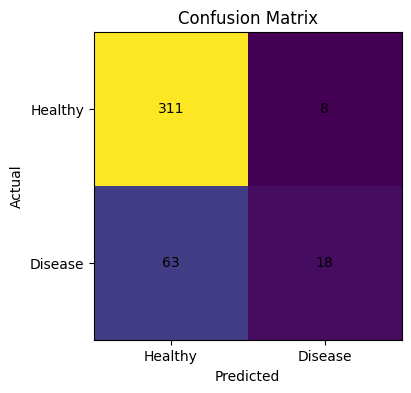

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks([0, 1], ["Healthy", "Disease"])
plt.yticks([0, 1], ["Healthy", "Disease"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.show()

## Summary of Results and Methodology

This notebook demonstrates how to effectively work with class-imbalanced datasets by comparing **Stratified Sampling** and **Random Sampling** strategies.

### 1. Dataset & Imbalance
- **Total samples**: 2,000 patients with 5 biomarker features.
- **Imbalance ratio**: Approximately **80% Healthy (1,596)** vs. **20% Disease-positive (404)**.

### 2. Random vs. Stratified Splitting
- **Random train_test_split**: Yielded slight deviations in class percentages between subsets (e.g., 21% Disease in the test set).
- **Stratified train_test_split**: Preserved the exact class ratios (~79.8% Healthy, ~20.2% Disease) in both training and test subsets.

### 3. Cross-Validation Setup
- We employed a 5-fold `StratifiedKFold` cross-validator to evaluate our model.
- **Mean F1 score** across folds: **~0.273** (with a standard deviation of **~0.055**).

### 4. Final Model Evaluation (Logistic Regression)
After training a Logistic Regression pipeline (with data standardization) on the stratified training set, we evaluated it on the test set:

- **Overall Accuracy**: 82% (heavily biased toward predicting the majority class).
- **Class 0 (Healthy)**: Precision of **83%**, Recall of **97%**, F1-score of **90%**.
- **Class 1 (Disease)**: Precision of **69%**, Recall of **22%**, F1-score of **34%**.

**Key Takeaway**: While stratifying splits preserves class distributions properly, a simple Logistic Regression model still struggles to effectively identify the positive class (low recall for "Disease") without addressing the imbalance directly (e.g., via class weights, oversampling, or threshold tuning).